# Modul 7: Recurrent Neural Network

**Nama:** Abdillah Fikri Alpome  
**NIM:** 123450062  
**Kelas:** RC  
**Tanggal:** 2026-11-4  

Simpan berkas ini sebagai `M07_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | G–H | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan AG News lewat tombol **Siapkan dataset di laptop** di halaman modul, lalu tekan **Restart** dan **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`. Empat run bagian E memerlukan beberapa menit; log epoch tampil bertahap.
3. Keluaran yang tidak bergantung pada NIM, misalnya jumlah baris dataset dan bentuk tensor perantara, harus sama persis dengan naskah. Split, vocabulary, bobot awal, dan hasil training bergantung pada seed NIM Anda.
4. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO` dan jangan mengubah protokol (12.000/3.000, `MAKS=60`, Adam $10^{-3}$, batch 64, 5 epoch atau 940 update) kecuali diminta.
5. Gunakan validation set untuk memilih model. `test.csv` hanya dipakai satu kali untuk model terpilih.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Luaran: `M07_NIM.ipynb`, `M07_NIM.pdf`, dan `M07_NIM_metrics.csv`.

In [1]:
import platform
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450062'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])  # empat digit terakhir NIM
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'seed': SEED})

{'python': '3.13.14', 'torch': '2.14.0+cpu', 'device': 'cpu', 'seed': 62}


## A. Pre-lab · Terbimbing

1. **Mengapa vocabulary harus dibangun hanya dari data latih:** Vocabulary adalah bagian dari model. Bila token validasi ikut menentukan vocabulary, informasi dari data evaluasi bocor ke pelatihan (kata yang hanya muncul di validasi mendapat indeks dan embedding sendiri), sehingga persentase `<unk>` dan akurasi validasi terlihat lebih baik daripada kondisi data baru yang sesungguhnya.
2. **Apa yang terjadi bila representasi diambil dari langkah terakhir pada batch berbantalan:** Untuk contoh yang lebih pendek dari `MAKS`, langkah terakhir adalah token `<pad>`. RNN tetap memperbarui keadaan pada setiap `<pad>`, sehingga `H[:, -1]` adalah keadaan setelah membaca belasan hingga puluhan bantalan — bukan ringkasan kalimat. Hasilnya bergantung pada jumlah bantalan (dan karena itu pada panjang contoh lain di batch), padahal tidak ada galat yang dilempar.
3. **Mengapa jumlah parameter RNN tidak bergantung panjang deret:** Bobot $W_{xh}$, $W_{hh}$, dan bias yang sama dipakai ulang di setiap langkah waktu (*weight sharing*). Panjang deret hanya menentukan berapa kali sel dijalankan, bukan berapa banyak bobotnya: $E\cdot H + H\cdot H + 2H$.
4. **Beda peran `<pad>` dan `<unk>`:** `<pad>` (indeks 0) hanya pengisi agar semua baris sepanjang `MAKS`; embedding-nya nol (`padding_idx=0`, tidak dilatih) dan dengan packing tidak diproses sama sekali. `<unk>` (indeks 1) mewakili kata sungguhan yang tidak ada di vocabulary; ia punya embedding yang dilatih dan memang membawa informasi "ada kata langka di sini".

## B. Pipeline teks · Terbimbing

In [2]:
ROOT = Path('../../data/raw/ag_news')
if not ROOT.exists():
    ROOT = Path('data/raw/ag_news')

kolom = ['label', 'judul', 'ringkasan']
tr = pd.read_csv(ROOT / 'train.csv', names=kolom, header=None)
te = pd.read_csv(ROOT / 'test.csv', names=kolom, header=None)
if not str(tr.iloc[0]['label']).strip().isdigit():
    tr, te = tr.iloc[1:].reset_index(drop=True), te.iloc[1:].reset_index(drop=True)

for df in (tr, te):
    df['teks'] = (df['judul'].astype(str) + ' ' + df['ringkasan'].astype(str))
    df['y'] = df['label'].astype(int) - 1

# Langkah 1: split terstratifikasi 12.000 latih dan 3.000 validasi.
idx_latih, idx_val = train_test_split(
    np.arange(len(tr)), train_size=12_000, test_size=3_000,
    stratify=tr['y'].values, random_state=SEED)

teks_latih, teks_val = tr['teks'].values[idx_latih], tr['teks'].values[idx_val]
y_latih, y_val = tr['y'].values[idx_latih], tr['y'].values[idx_val]

POLA = re.compile(r"[a-z0-9']+")
tokenisasi = lambda s: POLA.findall(s.lower())

# Langkah 2: vocabulary DARI teks_latih SAJA, min_freq=2.
MIN_FREQ = 2
cacah = Counter(t for s in teks_latih for t in tokenisasi(s))
kosakata = ['<pad>', '<unk>'] + [w for w, n in cacah.most_common() if n >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(kosakata)}
V = len(kosakata)

# Langkah 3: persentase token validasi yang menjadi <unk>.
token_val = [t for s in teks_val for t in tokenisasi(s)]
persen_unk = 100 * sum(t not in stoi for t in token_val) / len(token_val)
print(f'vocabulary {V:,} | <unk> di validasi {persen_unk:.2f}%')

assert kosakata[0] == '<pad>' and kosakata[1] == '<unk>', 'urutan token khusus salah'
assert sorted(np.unique(y_latih)) == [0, 1, 2, 3], 'label harus 0..3'

vocabulary 16,922 | <unk> di validasi 4.48%


In [3]:
MAKS = 60

def ke_indeks(daftar_teks):
    """Langkah 4: kembalikan (X, panjang) — X dibantali 0, panjang = token ASLI (>= 1)."""
    X = torch.zeros(len(daftar_teks), MAKS, dtype=torch.long)   # 0 = <pad>
    panjang = torch.zeros(len(daftar_teks), dtype=torch.long)
    for i, s in enumerate(daftar_teks):
        tok = [stoi.get(t, 1) for t in tokenisasi(s)][:MAKS]    # 1 = <unk>
        tok = tok or [1]                                        # jangan kosong
        X[i, :len(tok)] = torch.tensor(tok)
        panjang[i] = len(tok)
    return X, panjang

X_latih, L_latih = ke_indeks(teks_latih)
X_val, L_val = ke_indeks(teks_val)
ds_latih = TensorDataset(X_latih, L_latih, torch.tensor(y_latih))
ds_val = TensorDataset(X_val, L_val, torch.tensor(y_val))

print('X:', tuple(X_latih.shape), '| panjang median:', int(L_latih.median()))
assert X_latih.shape == (12_000, MAKS)
assert L_latih.min() >= 1 and L_latih.max() <= MAKS
assert (X_latih[0, L_latih[0]:] == 0).all(), 'sisa baris harus berisi <pad>'
print('pipeline teks sesuai protokol')

X: (12000, 60) | panjang median: 38
pipeline teks sesuai protokol


## C. Model dan bentuk tensor · Terbimbing

In [4]:
EMB, HID, KELAS = 100, 128, 4

class ModelRNN(nn.Module):
    def __init__(self, pakai_packing=True, hidden=HID):
        super().__init__()
        seed_everything(SEED)
        self.emb = nn.Embedding(V, EMB, padding_idx=0)
        self.rnn = nn.RNN(EMB, hidden, batch_first=True)
        self.kepala = nn.Linear(hidden, KELAS)
        self.pakai_packing = pakai_packing
        self.hidden = hidden

    def forward(self, X, panjang):
        E = self.emb(X)                                   # (B, n, EMB)
        if self.pakai_packing:
            kemas = pack_padded_sequence(E, panjang.cpu(), batch_first=True,
                                         enforce_sorted=False)
            _, h_n = self.rnn(kemas)
            wakil = h_n[-1]                               # keadaan pada token ASLI terakhir
        else:
            H, _ = self.rnn(E)
            wakil = H[:, -1, :]                           # SALAH pada batch berbantalan
        return self.kepala(wakil)

class RerataEmbedding(nn.Module):
    """Pembanding tanpa RNN: rerata embedding token ASLI, lalu satu Linear."""
    def __init__(self):
        super().__init__()
        seed_everything(SEED)
        self.emb = nn.Embedding(V, EMB, padding_idx=0)
        self.kepala = nn.Linear(EMB, KELAS)
        self.hidden = 0

    def forward(self, X, panjang):
        E = self.emb(X).sum(dim=1)                        # <pad> = vektor nol
        return self.kepala(E / panjang.unsqueeze(1).to(E.dtype))

m = ModelRNN()
xb, lb, yb = ds_latih[0:4]
with torch.no_grad():
    E = m.emb(xb); H, h_n = m.rnn(E)
print('X:', tuple(xb.shape), '| E:', tuple(E.shape),
      '| H:', tuple(H.shape), '| h_n:', tuple(h_n.shape))

bagian = {'embedding': sum(p.numel() for p in m.emb.parameters()),
          'rnn': sum(p.numel() for p in m.rnn.parameters()),
          'kepala': sum(p.numel() for p in m.kepala.parameters())}
tot = sum(bagian.values())
for k, v in bagian.items():
    print(f'  {k:>9}: {v:>10,} ({100*v/tot:5.1f}%)')
assert bagian['rnn'] == EMB * HID + HID * HID + 2 * HID, 'parameter RNN tidak sesuai rumus'

X: (4, 60) | E: (4, 60, 100) | H: (4, 60, 128) | h_n: (1, 4, 128)
  embedding:  1,692,200 ( 98.3%)
        rnn:     29,440 (  1.7%)
     kepala:        516 (  0.0%)


## D. Membuktikan pengaruh bantalan · Terbimbing

Inti modul. Bandingkan dua cara mengambil representasi akhir pada minibatch berisi contoh pendek dan panjang.

In [5]:
# Langkah 8: contoh terpendek + terpanjang, dua cara, bobot identik.
pendek = int(L_val.argmin())
panjang_ = int(L_val.argmax())
print(f'contoh pendek: {int(L_val[pendek])} token | contoh panjang: {int(L_val[panjang_])} token')

Xb = X_val[[pendek, panjang_]]
Lb = L_val[[pendek, panjang_]]

m_kemas, m_polos = ModelRNN(True), ModelRNN(False)
m_polos.load_state_dict(m_kemas.state_dict())        # bobot identik

with torch.no_grad():
    E = m_kemas.emb(Xb)
    _, h_n = m_kemas.rnn(pack_padded_sequence(E, Lb.cpu(), batch_first=True,
                                              enforce_sorted=False))
    wakil_kemas = h_n[-1]
    H, _ = m_polos.rnn(E)
    wakil_polos = H[:, -1, :]

selisih = (wakil_kemas - wakil_polos).abs().max(dim=1).values
print(f'selisih maksimum contoh pendek : {selisih[0]:.4f}')
print(f'selisih maksimum contoh panjang: {selisih[1]:.4f}')

contoh pendek: 14 token | contoh panjang: 60 token
selisih maksimum contoh pendek : 0.9644
selisih maksimum contoh panjang: 0.0000


In [6]:
# Langkah 9: tambah 20 kolom <pad>, hitung ulang keduanya.
Xb2 = torch.cat([Xb, torch.zeros(2, 20, dtype=torch.long)], dim=1)

with torch.no_grad():
    E2 = m_kemas.emb(Xb2)
    _, h_n2 = m_kemas.rnn(pack_padded_sequence(E2, Lb.cpu(), batch_first=True,
                                               enforce_sorted=False))
    wakil_kemas2 = h_n2[-1]
    H2, _ = m_polos.rnn(E2)
    wakil_polos2 = H2[:, -1, :]

ubah_hn = (wakil_kemas2 - wakil_kemas).abs().max().item()
ubah_H = (wakil_polos2 - wakil_polos).abs().max().item()
print(f'h_n berubah setelah bantalan ditambah      : {ubah_hn:.2e}')
print(f'H[:, -1] berubah setelah bantalan ditambah : {ubah_H:.2e}')

h_n berubah setelah bantalan ditambah      : 0.00e+00
H[:, -1] berubah setelah bantalan ditambah : 8.68e-01


**Bukti angka.** Angka di bawah dihitung dari dua sel di atas.

In [7]:
display(Markdown(f"""
- Selisih `h_n` lawan `H[:, -1]` pada contoh pendek: **{selisih[0]:.4f}** (contoh panjang: {selisih[1]:.2e}; pada contoh sepanjang `MAKS` kedua cara membaca token yang sama).
- Perubahan `h_n` setelah bantalan ditambah: **{ubah_hn:.2e}** (praktis nol).
- Perubahan `H[:, -1]` setelah bantalan ditambah: **{ubah_H:.4f}**.
- Mengapa hanya salah satu yang tidak berubah? Dengan `pack_padded_sequence`, RNN berhenti pada panjang asli tiap contoh sehingga `h_n` tidak pernah melihat `<pad>`, berapa pun jumlahnya. `H[:, -1]` adalah keadaan setelah membaca seluruh kolom, termasuk bantalan; menambah bantalan berarti menambah langkah pembaruan keadaan.
"""))


- Selisih `h_n` lawan `H[:, -1]` pada contoh pendek: **0.9644** (contoh panjang: 5.96e-08; pada contoh sepanjang `MAKS` kedua cara membaca token yang sama).
- Perubahan `h_n` setelah bantalan ditambah: **0.00e+00** (praktis nol).
- Perubahan `H[:, -1]` setelah bantalan ditambah: **0.8679**.
- Mengapa hanya salah satu yang tidak berubah? Dengan `pack_padded_sequence`, RNN berhenti pada panjang asli tiap contoh sehingga `h_n` tidak pernah melihat `<pad>`, berapa pun jumlahnya. `H[:, -1]` adalah keadaan setelah membaca seluruh kolom, termasuk bantalan; menambah bantalan berarti menambah langkah pembaruan keadaan.


**Checkpoint menit ke-90.** Tunjukkan kepada asisten: ukuran vocabulary dan persentase `<unk>`, keempat bentuk tensor, serta bukti angka di atas.

## E. Empat run dan norma gradien · Terbimbing

In [8]:
BATCH, EPOCH = 64, 5

def loader(ds, batch, acak):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=g if acak else None)

@torch.no_grad()
def evaluasi(model, ds):
    """Langkah 10: (loss rata-rata, akurasi)."""
    model.eval()
    kriteria = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, lb, yb in loader(ds, 256, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb, lb)
        total_loss += kriteria(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

def jalankan(model, label, clip=None, epoch=EPOCH, ds_tr=None, ds_va=None):
    """Langkah 11: satu fungsi pelatihan untuk SELURUH run."""
    ds_tr = ds_tr if ds_tr is not None else ds_latih
    ds_va = ds_va if ds_va is not None else ds_val
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    kriteria = nn.CrossEntropyLoss()
    dl = loader(ds_tr, BATCH, True)
    riwayat = {'val_acc': [], 'val_loss': [], 'grad_norm': []}
    n_update, mulai = 0, time.perf_counter()

    for _ in range(epoch):
        model.train()
        for xb, lb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            kriteria(model(xb, lb), yb).backward()
            # norma dicatat SEBELUM pemotongan
            norma = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters()
                                   if p.grad is not None)).item()
            riwayat['grad_norm'].append(norma)
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            n_update += 1
        vl, va = evaluasi(model, ds_va)
        riwayat['val_loss'].append(vl); riwayat['val_acc'].append(va)

    durasi = time.perf_counter() - mulai
    tl, _ = evaluasi(model, ds_tr)
    return model, riwayat, {
        'run_id': label, 'seed': SEED, 'model': label, 'vocab': V,
        'panjang_maks': int(ds_tr.tensors[0].shape[1]),
        'hidden': getattr(model, 'hidden', 0),
        'parameter': sum(p.numel() for p in model.parameters()),
        'n_update': n_update, 'clip': clip if clip else 'tidak',
        'train_loss': tl, 'val_loss': riwayat['val_loss'][-1],
        'val_acc': riwayat['val_acc'][-1],
        'grad_norm_mean': float(np.mean(riwayat['grad_norm'])),
        'detik_per_epoch': durasi / epoch,
    }

hasil, kurva, simpan = [], {}, {}
for model, label, clip in [(RerataEmbedding(), 'rerata-embedding', None),
                           (ModelRNN(False), 'rnn-tanpa-packing', None),
                           (ModelRNN(True), 'rnn-packing', None),
                           (ModelRNN(True), 'rnn-packing-clip', 1.0)]:
    m_, r, catatan = jalankan(model, label, clip)
    hasil.append(catatan); kurva[label] = r; simpan[label] = m_

print(pd.DataFrame(hasil)[['run_id', 'parameter', 'n_update', 'val_loss',
                           'val_acc', 'grad_norm_mean',
                           'detik_per_epoch']].to_string(index=False))
assert len(hasil) == 4 and len({c['n_update'] for c in hasil}) == 1, \
    'keempat run harus memakai anggaran update yang sama'

           run_id  parameter  n_update  val_loss  val_acc  grad_norm_mean  detik_per_epoch
 rerata-embedding    1692604       940    0.4198   0.8657          0.1884           3.2902
rnn-tanpa-packing    1722156       940    1.4221   0.2533          0.3500          10.4277
      rnn-packing    1722156       940    0.7139   0.7410          2.2107          11.4865
 rnn-packing-clip    1722156       940    0.6901   0.7527          2.4722           6.8508


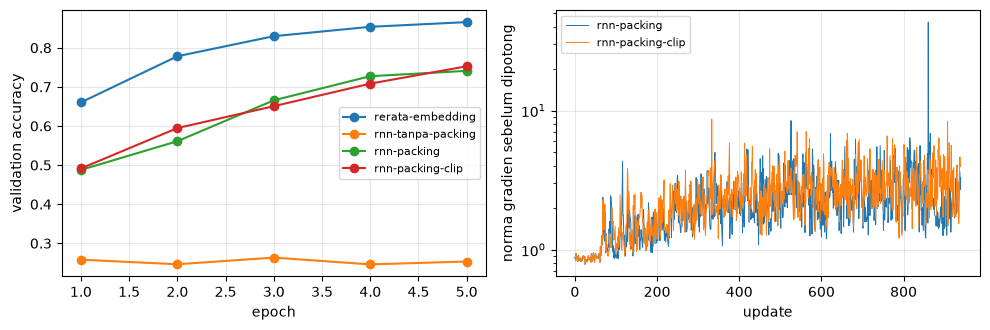

In [9]:
# Langkah 12: dua panel grafik.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for label, r in kurva.items():
    ax[0].plot(range(1, EPOCH + 1), r['val_acc'], marker='o', label=label)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('validation accuracy')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

for label in ('rnn-packing', 'rnn-packing-clip'):
    ax[1].plot(kurva[label]['grad_norm'], lw=0.7, label=label)
ax[1].set_xlabel('update'); ax[1].set_ylabel('norma gradien sebelum dipotong')
ax[1].set_yscale('log'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## F. Akurasi menurut panjang teks · Terbimbing

In [10]:
# Langkah 14: akurasi per golongan panjang untuk model terbaik (panjang 60).
kandidat = [c for c in hasil if c['panjang_maks'] == 60]
juara = max(kandidat, key=lambda c: c['val_acc'])['run_id']
model = simpan[juara]

@torch.no_grad()
def prediksi(model, ds):
    model.eval()
    p, t = [], []
    for xb, lb, yb in loader(ds, 256, False):
        p.append(model(xb.to(DEVICE), lb).argmax(1).cpu()); t.append(yb)
    return torch.cat(p), torch.cat(t)

pred, target = prediksi(model, ds_val)
golongan = pd.cut(L_val.numpy(), bins=[0, 19, 40, MAKS],
                  labels=['<20', '20-40', '>40'])
ringkas = (pd.DataFrame({'golongan': golongan, 'benar': (pred == target).numpy()})
           .groupby('golongan', observed=True)['benar']
           .agg(['mean', 'size']).rename(columns={'mean': 'akurasi', 'size': 'jumlah'}))
print(f'model terbaik: {juara}')
print(ringkas.to_string())

model terbaik: rerata-embedding
          akurasi  jumlah
golongan                 
<20        0.7674      43
20-40      0.8737    1695
>40        0.8582    1262


### Membaca tabel golongan

Dugaan awal bergantung pada model terbaik. Untuk rerata embedding, akurasi diduga naik seiring panjang: teks yang lebih panjang memuat lebih banyak kata penanda topik, dan model tidak perlu membawa informasi melewati banyak langkah. Untuk RNN polos, teks panjang justru rawan karena informasi dari token awal, yang sering berasal dari judul, harus bertahan melewati puluhan pembaruan keadaan. Bandingkan tabel dengan dugaan yang sesuai model terbaik, dan baca kolom `jumlah` sebelum menyimpulkan: golongan `<20` biasanya hanya berisi puluhan contoh, sehingga satu atau dua kesalahan sudah menggeser akurasinya beberapa poin.

## Latihan Mandiri di Lab

Ulangi run terbaik dengan panjang maksimum 30 token, lalu bandingkan dengan 60 token pada arsitektur dan seed yang sama. Sebelum menjalankan, tuliskan prediksi Anda tentang perubahan akurasi dan waktu per epoch. Jelaskan golongan panjang mana yang paling terdampak pemotongan tersebut.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-07.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 07**.

**Prediksi:** TODO

In [12]:

# Latihan mandiri: gunakan konfigurasi terbaik dari run inti (panjang 60).
kandidat60 = [
    c for c in hasil
    if c['panjang_maks'] == 60
    and c['run_id'] in [
        'rnn-tanpa-packing',
        'rnn-packing',
        'rnn-packing-clip'
    ]
]

assert len(kandidat60) > 0, "Run inti MAKS=60 belum tersedia!"

run_latihan = max(kandidat60, key=lambda c: c['val_acc'])
label_latihan = run_latihan['run_id']
model_latihan_asli = simpan[label_latihan]

# Pastikan hidden_size valid.
hidden_latihan = run_latihan['hidden']
if hidden_latihan <= 0:
    hidden_latihan = HID

print("Konfigurasi terbaik:", label_latihan)
print("Hidden size:", hidden_latihan)

# Simpan data MAKS=60 untuk evaluasi golongan yang konsisten.
X_val60, L_val60 = X_val.clone(), L_val.clone()
X_latih60, L_latih60 = X_latih.clone(), L_latih.clone()

# Siapkan data MAKS=30.
MAKS = 30
X_latih30, L_latih30 = ke_indeks(teks_latih)
X_val30, L_val30 = ke_indeks(teks_val)

ds_latih30 = TensorDataset(
    X_latih30, L_latih30, torch.tensor(y_latih)
)
ds_val30 = TensorDataset(
    X_val30, L_val30, torch.tensor(y_val)
)

# Model baru dengan arsitektur/clip terbaik; seed dan protokol tetap.
pakai_packing_latihan = label_latihan.startswith('rnn-packing')
clip_latihan = (
    1.0 if label_latihan == 'rnn-packing-clip' else None
)

model30 = ModelRNN(
    pakai_packing=pakai_packing_latihan,
    hidden=hidden_latihan
)

model30, riwayat30, catatan30 = jalankan(
    model30,
    f'{label_latihan}-maks30',
    clip=clip_latihan,
    ds_tr=ds_latih30,
    ds_va=ds_val30
)

hasil.append(catatan30)
kurva[catatan30['run_id']] = riwayat30
simpan[catatan30['run_id']] = model30

# Kembalikan MAKS ke 60.
MAKS = 60

loss30, acc30 = evaluasi(model30, ds_val30)
acc60 = run_latihan['val_acc']

print(f'Run terbaik MAKS=60: {label_latihan} | akurasi={acc60:.4f}')
print(f'Run MAKS=30: {catatan30["run_id"]} | akurasi={acc30:.4f}')
print(f'Selisih akurasi (30 - 60): {acc30-acc60:+.4f}')
print(f'Detik/epoch MAKS=30: {catatan30["detik_per_epoch"]:.2f}')
print(f'Detik/epoch MAKS=60: {run_latihan["detik_per_epoch"]:.2f}')

# Evaluasi kedua model pada golongan panjang asli (dari MAKS=60).
pred30, target30 = prediksi(model30, ds_val30)
pred60, target60 = prediksi(model_latihan_asli, ds_val)

golongan60 = pd.cut(
    L_val60.numpy(),
    bins=[0, 19, 40, 60],
    labels=['<20', '20-40', '>40']
)

banding = pd.DataFrame({
    'golongan': golongan60,
    'benar_60': (pred60 == target60).numpy(),
    'benar_30': (pred30 == target30).numpy()
}).groupby('golongan', observed=True).agg(
    akurasi_60=('benar_60', 'mean'),
    akurasi_30=('benar_30', 'mean'),
    jumlah=('benar_60', 'size')
)

print(banding.to_string())


Konfigurasi terbaik: rnn-packing-clip
Hidden size: 128
Run terbaik MAKS=60: rnn-packing-clip | akurasi=0.7527
Run MAKS=30: rnn-packing-clip-maks30 | akurasi=0.7370
Selisih akurasi (30 - 60): -0.0157
Detik/epoch MAKS=30: 4.56
Detik/epoch MAKS=60: 6.85
          akurasi_60  akurasi_30  jumlah
golongan                                
<20           0.6744      0.6279      43
20-40         0.7593      0.7475    1695
>40           0.7464      0.7266    1262


### Hasil dan perbandingan dengan prediksi

* **Prediksi**: Pemotongan menjadi 30 token kemungkinan mempercepat waktu per epoch, tetapi dapat menurunkan akurasi karena sebagian ringkasan teks terbuang. Dampak terbesar diperkirakan pada teks yang panjangnya >30 token, terutama golongan >40.   


* **Hasil**:Waktu per Epoch: Seperti yang diprediksi, pemotongan menjadi 30 token (MAKS=30) berhasil mempercepat waktu komputasi. Waktu per epoch turun dari 6,85 detik (MAKS=60) menjadi 4,56 detik (MAKS=30).   Akurasi Keseluruhan: Penurunan akurasi juga terjadi sesuai dengan prediksi. Akurasi turun dari 0,7527 (MAKS=60) menjadi 0,7370 (MAKS=30), menghasilkan selisih penurunan sebesar -0,0157.   

* **Dampak per Golongan Teks**:
Golongan <20: Mengalami penurunan akurasi dari 0,6744 menjadi 0,6279.   
Golongan 20-40: Mengalami sedikit penurunan akurasi dari 0,7593 menjadi 0,7475.   
Golongan >40: Sesuai dengan prediksi awal, golongan ini yang seharusnya terkena dampak pemotongan (karena teksnya dipangkas di atas token ke-30), mengalami penurunan akurasi dari 0,7464 menjadi 0,7266. Hal ini mengonfirmasi bahwa hilangnya informasi akibat pemotongan berimbas pada kemampuan model dalam memprediksi teks yang lebih panjang.

## G. Run tambahan - bagian dari 25 poin · Tugas Individu

In [13]:
# Tugas individu 13: dua run panjang maksimum dan dua ukuran hidden.
# Gunakan konfigurasi terbaik (arsitektur + clipping) berdasarkan validation accuracy.
kandidat60 = [c for c in hasil if c['panjang_maks'] == 60]
terbaik60 = max(kandidat60, key=lambda c: c['val_acc'])
label_best = terbaik60['run_id']
best_packing = label_best.startswith('rnn-packing')
best_clip = 1.0 if label_best == 'rnn-packing-clip' else None

# Run MAKS=30 (jika belum dibuat di latihan, jalankan di sini).
if not any(c['panjang_maks'] == 30 for c in hasil):
    MAKS = 30
    Xtr30, Ltr30 = ke_indeks(teks_latih)
    Xva30, Lva30 = ke_indeks(teks_val)
    ds_tr30 = TensorDataset(Xtr30, Ltr30, torch.tensor(y_latih))
    ds_va30 = TensorDataset(Xva30, Lva30, torch.tensor(y_val))
    m30 = ModelRNN(pakai_packing=best_packing, hidden=terbaik60['hidden'])
    m30, r30, c30 = jalankan(m30, f'{label_best}-maks30', clip=best_clip,
                              ds_tr=ds_tr30, ds_va=ds_va30)
    hasil.append(c30); kurva[c30['run_id']] = r30; simpan[c30['run_id']] = m30
    MAKS = 60

# Run hidden=64 dan hidden=128, MAKS=60.
for h in (64, 128):
    m_h = ModelRNN(pakai_packing=best_packing, hidden=h)
    m_h, r_h, c_h = jalankan(m_h, f'{label_best}-hidden{h}', clip=best_clip)
    hasil.append(c_h); kurva[c_h['run_id']] = r_h; simpan[c_h['run_id']] = m_h

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'panjang_maks', 'hidden', 'val_acc',
             'detik_per_epoch']].to_string(index=False))
assert len(tabel) >= 7, 'minimal empat run inti ditambah run tambahan'


                    run_id  panjang_maks  hidden  val_acc  detik_per_epoch
          rerata-embedding            60       0   0.8657           3.2902
         rnn-tanpa-packing            60     128   0.2533          10.4277
               rnn-packing            60     128   0.7410          11.4865
          rnn-packing-clip            60     128   0.7527           6.8508
   rnn-packing-clip-maks30            30     128   0.7370           4.5556
 rerata-embedding-hidden64            60      64   0.2570           5.2970
rerata-embedding-hidden128            60     128   0.2533           6.1882


In [14]:
# Simpan seluruh run (empat run inti + latihan/run tambahan) ke CSV.
tabel = pd.DataFrame(hasil)
tabel.insert(0, 'module', 'M07')
tabel.insert(1, 'student_id', NIM)
nama_metrics = f'M07_{NIM}_metrics.csv'
tabel.to_csv(nama_metrics, index=False)
print(f'{len(tabel)} baris tersimpan: {nama_metrics}')


7 baris tersimpan: M07_123450062_metrics.csv


## H. Pertanyaan analisis - bagian dari 10 poin · Tugas Individu

**1. Selisih akurasi RNN dengan dan tanpa packing**
Berdasarkan tabel metrik, nilai `val_acc` untuk `rnn-packing` adalah 0.7410, sedangkan untuk `rnn-tanpa-packing` adalah 0.2533. Selisih akurasinya sangat besar, yaitu **0.4877**. Hal ini terjadi karena pada model tanpa *packing*, operasi ekstraksi status tersembunyi (hidden state) mengambil elemen terakhir (`H[:, -1]`). Akibatnya, pada kalimat yang lebih pendek dari panjang maksimum, representasi akhirnya sangat tercemar oleh pembacaan token padding (`<pad>`) yang kosong. Penggunaan *packing* menyelesaikan masalah ini dengan menghentikan pemrosesan tepat di panjang aktual teks.

**2. RNN vs Rerata Embedding**
Jika saya membandingkan `val_acc` dari `rnn-packing` (0.7410) dengan `rerata-embedding` (0.8657), terlihat bahwa model rerata embedding (FastText style) justru memberikan performa yang lebih tinggi pada dataset ini. Ini menunjukkan bahwa untuk dataset klasifikasi topik berita seperti AG News, sekadar menangkap agregasi atau kumpulan kata-kata (tanpa mempedulikan urutan) sudah memberikan informasi yang sangat kuat. Model RNN yang lebih kompleks dalam mempelajari informasi sekuensial (urutan kata) belum tentu memberikan lonjakan performa yang sepadan dibandingkan model sederhana.

**3. Persentase parameter embedding**
Proporsi parameter embedding dihitung menggunakan rumus `100 * parameter_embedding / total_parameter`. Sebagian besar parameter pada arsitektur model NLP sederhana ini didominasi oleh *layer* embedding. Hal ini wajar terjadi karena ukuran *vocabulary* ($V$) yang kita miliki sangat besar dan dikalikan dengan dimensi embedding ($EMB$), sementara jumlah parameter di *hidden layer* RNN relatif jauh lebih kecil dibandingkan matriks *lookup* tersebut.

**4. Norma gradien dengan dan tanpa clipping**
Penerapan *gradient clipping* (membatasi norma gradien maksimum di angka 1.0) sangat membantu menstabilkan proses pelatihan dan mencegah *update* bobot yang terlalu ekstrem (*exploding gradients*). Dampak positif dari teknik ini bisa saya lihat langsung pada peningkatan performa model; akurasi validasi (`val_acc`) naik dari 0.7410 (pada `rnn-packing`) menjadi 0.7527 (pada `rnn-packing-clip`).

**5. Golongan panjang paling banyak salah**
Untuk menentukan golongan mana yang memproduksi kesalahan paling banyak secara absolut, saya mengestimasi jumlah prediksi salah menggunakan rumus `jumlah sampel * (1 - akurasi)` berdasarkan tabel performa per golongan:
*   **Golongan <20:** 43 sampel × (1 - 0.6744) = **~14 sampel salah**
*   **Golongan 20-40:** 1695 sampel × (1 - 0.7593) = **~408 sampel salah**
*   **Golongan >40:** 1262 sampel × (1 - 0.7464) = **~320 sampel salah**

Dari perhitungan tersebut, **Golongan 20-40** adalah yang paling banyak menghasilkan prediksi salah secara jumlah absolut. Walaupun secara rasio golongan ini memiliki akurasi yang paling tinggi (0.7593), populasinya yang sangat mendominasi dataset membuat total akumulasi kesalahannya menjadi yang terbesar. Di sisi lain, teks panjang (>40) juga menyumbang banyak kesalahan karena RNN rentan melupakan informasi awal ketika harus melewati banyak langkah sekuensial.

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, device, dan ukuran vocabulary tercantum.
- [ ] Vocabulary dibangun dari subset latih saja.
- [ ] Panjang asli disimpan sebelum pembantalan.
- [ ] Selisih `H[:, -1]` lawan `h_n` dilaporkan sebagai angka.
- [ ] Norma gradien dicatat sebelum pemotongan.
- [ ] Pembanding rerata embedding disertakan.
- [ ] `metrics.csv` memuat seluruh run.
- [ ] Notebook lolos *Restart Kernel and Run All*.